In [1]:
# Week 4 Assignment: Statistics, Data Visualization & EDA
# Step 1: Import libraries and set up the environment

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("outputs", exist_ok=True)   # folder to save charts and CSV files
sns.set_theme(style="whitegrid")        # clean chart style
rng = np.random.default_rng(42)         # fixed seed, so results are the same every time

print("Setup complete")

Setup complete


In [2]:
# Cell 2: Create the synthetic retail sales dataset (300 rows)

n = 300
df = pd.DataFrame({
    "OrderID": range(1, n + 1),
    "Month": rng.choice(["Jan", "Feb", "Mar", "Apr", "May", "Jun"], n),
    "Category": rng.choice(["Electronics", "Clothing", "Grocery", "Furniture"], n, p=[.3, .3, .25, .15]),
    "Region": rng.choice(["North", "South", "East", "West"], n),
    "Quantity": rng.integers(1, 10, n),
    "UnitPrice": rng.normal(60, 20, n).round(2).clip(5),
    "AdSpend": rng.normal(100, 30, n).round(2).clip(10),
})

# Sales depends on quantity, price and ad spend, plus some random noise
df["Sales"] = (df.Quantity * df.UnitPrice + df.AdSpend * 1.5 + rng.normal(0, 25, n)).round(2)
df["Rating"] = rng.integers(1, 6, n).astype(float)

# Deliberately add "dirty" data so the cleaning task has real work to do
df.loc[[5, 50, 120], "Sales"] = [2500, 2800, 3000]                          # outliers
df.loc[rng.choice(n, 15, replace=False), "Rating"] = np.nan                 # missing values
df.loc[rng.choice(n, 10, replace=False), "UnitPrice"] = np.nan              # missing values
df.loc[[10, 20, 30], "Category"] = ["electronics ", "CLOTHING", "grocery"]  # inconsistent text
df.loc[[40, 41], "Quantity"] = [-3, -1]                                     # incorrect values
df = pd.concat([df, df.sample(8, random_state=1)], ignore_index=True)       # duplicate rows

df.to_csv("outputs/sales_raw.csv", index=False)   # save the raw dataset
raw = df.copy()                                   # keep an untouched copy for "before" results

print("Dataset created:", df.shape)
df.head()

Dataset created: (308, 9)


,OrderID,Month,Category,Region,Quantity,UnitPrice,AdSpend,Sales,Rating
0,1,Jan,Grocery,North,8,58.08,110.20,610.93,1.0
1,2,May,Furniture,North,5,82.56,109.48,563.00,1.0
2,3,Apr,Electronics,North,9,14.39,112.29,297.39,4.0
3,4,Mar,Clothing,West,7,30.07,118.48,349.14,4.0
4,5,Mar,Electronics,South,6,41.54,36.76,310.10,3.0


In [3]:
# Cell 3: Task 1 - Mean, Median and Mode

s = raw["Sales"].dropna()   # Sales values without missing entries

mean_val = s.mean()
median_val = s.median()
mode_val = s.mode().iloc[0]

print("Mean   :", round(mean_val, 2))
print("Median :", round(median_val, 2))
print("Mode   :", mode_val)
print("Quantity mode (most common quantity):", raw["Quantity"].mode().iloc[0])

print("""
Explanation:
- Mean is the average sales per order. It is pulled upward by the extreme values (outliers).
- Median is the middle value when sales are sorted. It shows the typical order and is not affected by outliers.
- Mode is the most frequently occurring value. It is most useful for discrete data such as Quantity.
- Mean is greater than median here, so the data is right-skewed because of a few very large orders.
""")

Mean   : 471.16
Median : 433.04
Mode   : 247.65
Quantity mode (most common quantity): 3

Explanation:
- Mean is the average sales per order. It is pulled upward by the extreme values (outliers).
- Median is the middle value when sales are sorted. It shows the typical order and is not affected by outliers.
- Mode is the most frequently occurring value. It is most useful for discrete data such as Quantity.
- Mean is greater than median here, so the data is right-skewed because of a few very large orders.



In [4]:
# Cell 4: Task 2 - Variance and Standard Deviation

variance_val = s.var()   # sample variance of Sales
std_val = s.std()        # sample standard deviation of Sales

print("Variance           :", round(variance_val, 2))
print("Standard Deviation :", round(std_val, 2))
print("Mean               :", round(s.mean(), 2))
print("Std Dev as % of mean:", round(std_val / s.mean() * 100, 1), "%")

print("""
Explanation:
- Variance measures how far the sales values are spread out from the mean (in squared units).
- Standard deviation is the square root of variance, so it is in the same unit as Sales.
- It tells us that a typical order differs from the average by about this amount.
- A large standard deviation means the sales are widely spread; a small one means they cluster near the mean.
- Here the spread is inflated by a few extreme outliers, which we handle later in the cleaning step.
""")

Variance           : 91702.76
Standard Deviation : 302.82
Mean               : 471.16
Std Dev as % of mean: 64.3 %

Explanation:
- Variance measures how far the sales values are spread out from the mean (in squared units).
- Standard deviation is the square root of variance, so it is in the same unit as Sales.
- It tells us that a typical order differs from the average by about this amount.
- A large standard deviation means the sales are widely spread; a small one means they cluster near the mean.
- Here the spread is inflated by a few extreme outliers, which we handle later in the cleaning step.



In [5]:
# Cell 5: Task 3 - Correlation and Probability

# ---------- Part A: Correlation ----------
r = raw["AdSpend"].corr(raw["Sales"])   # Pearson correlation between two numerical variables

print("Correlation between AdSpend and Sales:", round(r, 3))

if r >= 0.5:
    strength = "strong positive"
elif r >= 0.3:
    strength = "moderate positive"
elif r > -0.3:
    strength = "weak"
elif r > -0.5:
    strength = "moderate negative"
else:
    strength = "strong negative"

print("Relationship:", strength)

print("""
Explanation (Correlation):
- Correlation ranges from -1 to +1.
- A positive value means that when Ad Spend increases, Sales tend to increase too.
- A value close to 0 means there is only a weak or no linear relationship.
- Correlation does not prove that one variable causes the other.
""")

# ---------- Part B: Probability ----------
# Real-world example 1: if we pick one order at random, what is the chance it is an Electronics order?
total_orders = len(raw)
electronics_orders = (raw["Category"] == "Electronics").sum()
p_electronics = electronics_orders / total_orders

print("Total orders           :", total_orders)
print("Electronics orders     :", electronics_orders)
print("P(order is Electronics):", round(p_electronics, 3), f"({round(p_electronics * 100, 1)}%)")

# Real-world example 2: what is the chance that a customer gives a rating of 4 or more?
ratings = raw["Rating"].dropna()
p_good_rating = (ratings >= 4).mean()
print("P(Rating >= 4)         :", round(p_good_rating, 3), f"({round(p_good_rating * 100, 1)}%)")

print("""
Explanation (Probability):
- Probability = favourable outcomes / total outcomes.
- If we pick one order at random, the chance that it is an Electronics order is the value shown above.
- About that percentage of customers give a good rating (4 or 5 stars).
- Probability values always lie between 0 and 1.
""")

Correlation between AdSpend and Sales: 0.219
Relationship: weak

Explanation (Correlation):
- Correlation ranges from -1 to +1.
- A positive value means that when Ad Spend increases, Sales tend to increase too.
- A value close to 0 means there is only a weak or no linear relationship.
- Correlation does not prove that one variable causes the other.

Total orders           : 308
Electronics orders     : 97
P(order is Electronics): 0.315 (31.5%)
P(Rating >= 4)         : 0.411 (41.1%)

Explanation (Probability):
- Probability = favourable outcomes / total outcomes.
- If we pick one order at random, the chance that it is an Electronics order is the value shown above.
- About that percentage of customers give a good rating (4 or 5 stars).
- Probability values always lie between 0 and 1.



Q1  : 281.87
Q3  : 590.9
IQR : 309.03
Outlier bounds: -181.68 to 1054.45

Number of outliers: 4
     OrderID     Category    Sales
5          6      Grocery  2500.00
50        51      Grocery  2800.00
120      121  Electronics  3000.00
126      127     Clothing  1094.49


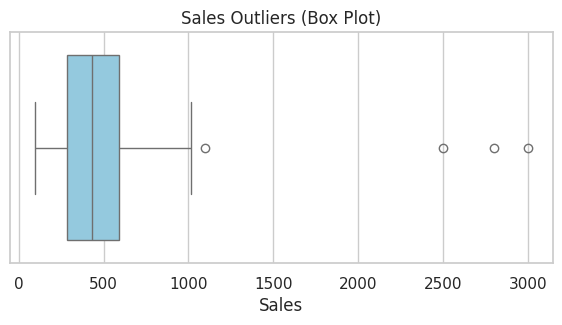


Saved files: ['sales_raw.csv', 'outliers.png']

Explanation:
- The IQR method treats any value below Q1 - 1.5*IQR or above Q3 + 1.5*IQR as a potential outlier.
- The points far to the right of the box plot are the outliers (very large orders).
- Outliers inflate the mean, variance and standard deviation, distort correlation, and can mislead models.
- They may be data entry errors or genuine big orders, so they must be investigated before being removed.



In [7]:
# Cell 6: Task 4 - Outlier detection using the IQR method

s = raw["Sales"].dropna()   # needed here in case Cell 3 was not run

Q1 = s.quantile(0.25)   # 25th percentile
Q3 = s.quantile(0.75)   # 75th percentile
IQR = Q3 - Q1           # interquartile range

lo = Q1 - 1.5 * IQR     # lower bound
hi = Q3 + 1.5 * IQR     # upper bound

print("Q1  :", round(Q1, 2))
print("Q3  :", round(Q3, 2))
print("IQR :", round(IQR, 2))
print(f"Outlier bounds: {lo:.2f} to {hi:.2f}")

# Rows whose Sales fall outside the bounds are outliers
outliers = raw[(raw["Sales"] < lo) | (raw["Sales"] > hi)]
print("\nNumber of outliers:", len(outliers))
print(outliers[["OrderID", "Category", "Sales"]])

# Box plot to show the outliers visually
plt.figure(figsize=(7, 3))
sns.boxplot(x=raw["Sales"], color="skyblue")
plt.title("Sales Outliers (Box Plot)")
plt.xlabel("Sales")
plt.savefig("outputs/outliers.png", bbox_inches="tight")
plt.show()

print("\nSaved files:", os.listdir("outputs"))

print("""
Explanation:
- The IQR method treats any value below Q1 - 1.5*IQR or above Q3 + 1.5*IQR as a potential outlier.
- The points far to the right of the box plot are the outliers (very large orders).
- Outliers inflate the mean, variance and standard deviation, distort correlation, and can mislead models.
- They may be data entry errors or genuine big orders, so they must be investigated before being removed.
""")

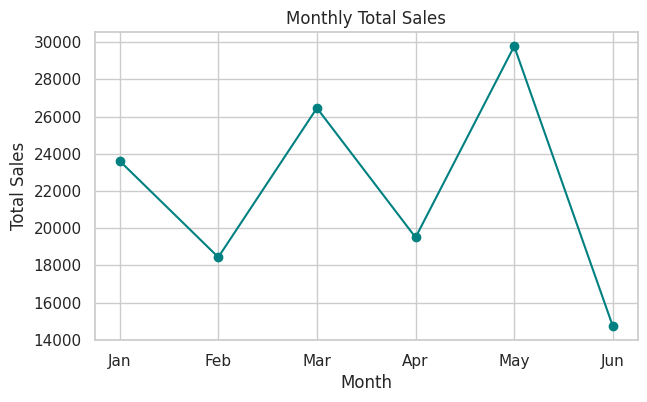

Line chart: shows how total sales change from month to month, so we can spot the best and weakest months.



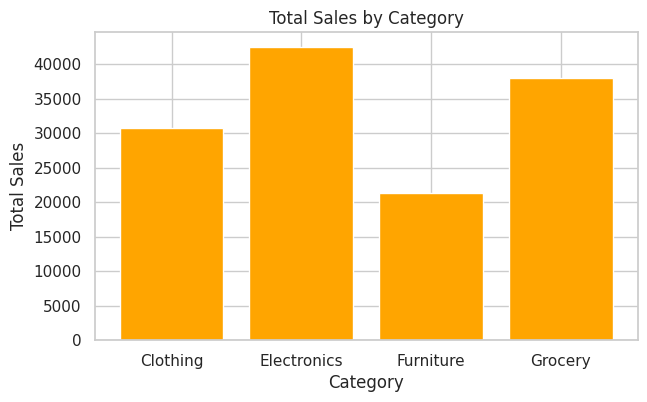

Bar chart: compares the categories. The tallest bar is the category that earns the most revenue.



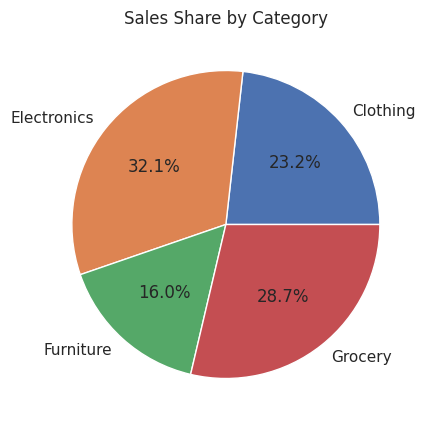

Pie chart: shows the percentage contribution of each category to total sales.



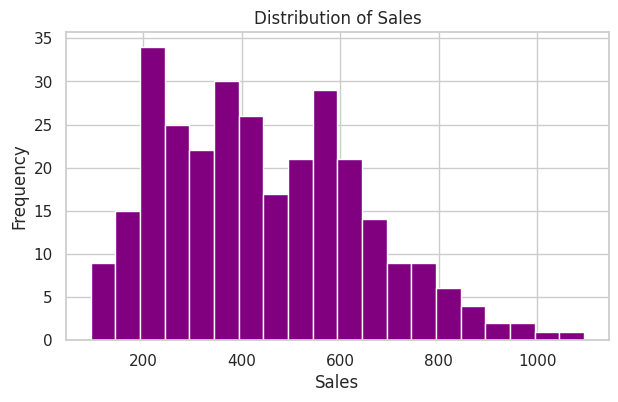

Histogram: shows the shape of the sales distribution. Most orders fall in the middle range.



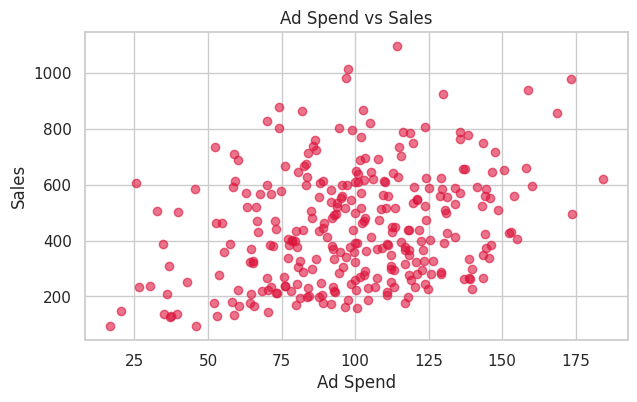

Scatter plot: each dot is one order. An upward drift means higher ad spend tends to go with higher sales.


In [8]:
# Cell 7: Task 5 - Matplotlib visualizations (Line, Bar, Pie, Histogram, Scatter)

# Prepare data for the charts: remove duplicates, missing Sales and extreme outliers, fix category text
tmp = raw.drop_duplicates().dropna(subset=["Sales"])
tmp = tmp[tmp["Sales"] < 1500]
tmp = tmp.assign(Category=tmp["Category"].str.strip().str.title())

order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
monthly = tmp.groupby("Month")["Sales"].sum().reindex(order)
cat_sales = tmp.groupby("Category")["Sales"].sum()

# ---------- 1. Line chart ----------
plt.figure(figsize=(7, 4))
plt.plot(monthly.index, monthly.values, marker="o", color="teal")
plt.title("Monthly Total Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.savefig("outputs/m_line.png", bbox_inches="tight")
plt.show()
print("Line chart: shows how total sales change from month to month, so we can spot the best and weakest months.\n")

# ---------- 2. Bar chart ----------
plt.figure(figsize=(7, 4))
plt.bar(cat_sales.index, cat_sales.values, color="orange")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.savefig("outputs/m_bar.png", bbox_inches="tight")
plt.show()
print("Bar chart: compares the categories. The tallest bar is the category that earns the most revenue.\n")

# ---------- 3. Pie chart ----------
plt.figure(figsize=(5, 5))
plt.pie(cat_sales.values, labels=cat_sales.index, autopct="%1.1f%%")
plt.title("Sales Share by Category")
plt.savefig("outputs/m_pie.png", bbox_inches="tight")
plt.show()
print("Pie chart: shows the percentage contribution of each category to total sales.\n")

# ---------- 4. Histogram ----------
plt.figure(figsize=(7, 4))
plt.hist(tmp["Sales"], bins=20, color="purple", edgecolor="white")
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.savefig("outputs/m_hist.png", bbox_inches="tight")
plt.show()
print("Histogram: shows the shape of the sales distribution. Most orders fall in the middle range.\n")

# ---------- 5. Scatter plot ----------
plt.figure(figsize=(7, 4))
plt.scatter(tmp["AdSpend"], tmp["Sales"], alpha=0.6, color="crimson")
plt.title("Ad Spend vs Sales")
plt.xlabel("Ad Spend")
plt.ylabel("Sales")
plt.savefig("outputs/m_scatter.png", bbox_inches="tight")
plt.show()
print("Scatter plot: each dot is one order. An upward drift means higher ad spend tends to go with higher sales.")

In [9]:
# Cell 8: Task 7 (Part 1) - Data inspection on the raw dataset

# 1. Number of rows and columns
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

# 2. Column names
print("\nColumn names:", list(df.columns))

# 3. Data types
print("\nData types:")
print(df.dtypes)

# 4. Statistical summary
print("\nStatistical summary:")
display(df.describe())

# 5. Quick quality checks (these show what needs cleaning)
print("\nMissing values per column:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nCategory values (look for inconsistent text):")
print(df["Category"].value_counts())

print("\nRows with negative Quantity:", (df["Quantity"] < 0).sum())

print("""
Findings:
- Missing values are present in UnitPrice and Rating.
- There are duplicate rows that must be removed.
- Category has inconsistent text (extra spaces and different capitalisation).
- Quantity has negative values, which are not possible for real orders.
- Sales has extreme values (outliers).
""")

Rows    : 308
Columns : 9

Column names: ['OrderID', 'Month', 'Category', 'Region', 'Quantity', 'UnitPrice', 'AdSpend', 'Sales', 'Rating']

Data types:
OrderID        int64
Month         object
Category      object
Region        object
Quantity       int64
UnitPrice    float64
AdSpend      float64
Sales        float64
Rating       float64
dtype: object

Statistical summary:


,OrderID,Quantity,UnitPrice,AdSpend,Sales,Rating
count,308.000000,308.000000,298.000000,308.000000,308.000000,292.000000
mean,150.487013,5.019481,59.849128,99.323604,471.159610,2.989726
std,85.922527,2.696290,19.908861,30.526931,302.824641,1.410526
min,1.000000,-3.000000,5.000000,16.660000,93.570000,1.000000
25%,76.750000,3.000000,46.720000,79.770000,281.872500,2.000000
50%,150.500000,5.000000,60.620000,100.065000,433.040000,3.000000
75%,223.250000,7.250000,72.577500,119.532500,590.905000,4.000000
max,300.000000,9.000000,123.580000,184.280000,3000.000000,5.000000



Missing values per column:
OrderID       0
Month         0
Category      0
Region        0
Quantity      0
UnitPrice    10
AdSpend       0
Sales         0
Rating       16
dtype: int64

Duplicate rows: 8

Category values (look for inconsistent text):
Category
Electronics     97
Grocery         85
Clothing        75
Furniture       48
electronics      1
CLOTHING         1
grocery          1
Name: count, dtype: int64

Rows with negative Quantity: 2

Findings:
- Missing values are present in UnitPrice and Rating.
- There are duplicate rows that must be removed.
- Category has inconsistent text (extra spaces and different capitalisation).
- Quantity has negative values, which are not possible for real orders.
- Sales has extreme values (outliers).



BEFORE cleaning: (308, 9)


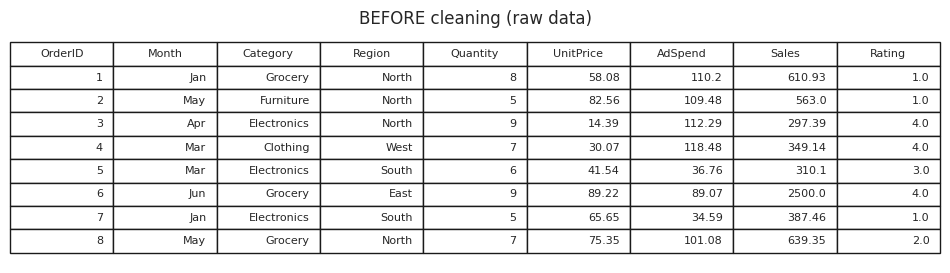

AFTER cleaning: (300, 10)
Missing values left: 0
Duplicates left   : 0
Categories now    : ['Grocery', 'Furniture', 'Electronics', 'Clothing']
Negative quantity : 0
Outliers flagged  : 4
Rows used for analysis: 296


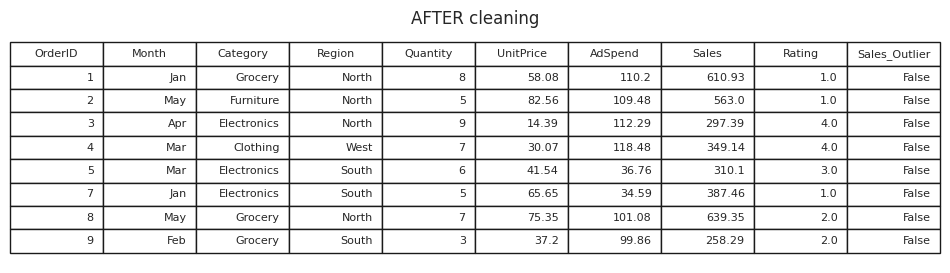


Cleaning summary:
- Duplicates removed so no order is counted twice.
- Category text standardised, so 'electronics ' and 'Electronics' are the same group.
- Negative quantities corrected, since an order cannot have a negative quantity.
- Missing values filled with the median, which keeps the data size and is robust to outliers.
- Extreme sales values flagged and excluded from the analysis dataset.



In [10]:
# Cell 9: Task 7 (Part 2) - Data cleaning with before/after screenshots

def table_image(d, title, path):
    """Save the first 8 rows of a DataFrame as a PNG image (used as a screenshot)."""
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.axis("off")
    t = ax.table(cellText=d.head(8).values, colLabels=d.columns, loc="center")
    t.auto_set_font_size(False)
    t.set_fontsize(8)
    t.scale(1, 1.4)
    ax.set_title(title)
    plt.savefig(path, bbox_inches="tight", dpi=150)
    plt.show()

# ---------- BEFORE cleaning ----------
print("BEFORE cleaning:", df.shape)
table_image(raw, "BEFORE cleaning (raw data)", "outputs/before_cleaning.png")

# ---------- Cleaning steps ----------
# 1. Remove duplicate rows
df = df.drop_duplicates()

# 2. Fix inconsistent text in Category (remove spaces, same capitalisation)
df["Category"] = df["Category"].str.strip().str.title()

# 3. Fix incorrect values: negative Quantity is a sign entry error, so make it positive
df.loc[df["Quantity"] < 0, "Quantity"] = df.loc[df["Quantity"] < 0, "Quantity"].abs()

# 4. Handle missing values with the median (not affected by outliers)
df["UnitPrice"] = df["UnitPrice"].fillna(df["UnitPrice"].median())
df["Rating"] = df["Rating"].fillna(df["Rating"].median())

# 5. Flag outliers (IQR bounds from Cell 6) and build the analysis dataset without them
df["Sales_Outlier"] = (df["Sales"] < lo) | (df["Sales"] > hi)
clean = df[~df["Sales_Outlier"]].copy()

# ---------- AFTER cleaning ----------
print("AFTER cleaning:", df.shape)
print("Missing values left:", df.isna().sum().sum())
print("Duplicates left   :", df.duplicated().sum())
print("Categories now    :", list(df["Category"].unique()))
print("Negative quantity :", (df["Quantity"] < 0).sum())
print("Outliers flagged  :", df["Sales_Outlier"].sum())
print("Rows used for analysis:", len(clean))

table_image(clean, "AFTER cleaning", "outputs/after_cleaning.png")
clean.to_csv("outputs/sales_clean.csv", index=False)

print("""
Cleaning summary:
- Duplicates removed so no order is counted twice.
- Category text standardised, so 'electronics ' and 'Electronics' are the same group.
- Negative quantities corrected, since an order cannot have a negative quantity.
- Missing values filled with the median, which keeps the data size and is robust to outliers.
- Extreme sales values flagged and excluded from the analysis dataset.
""")

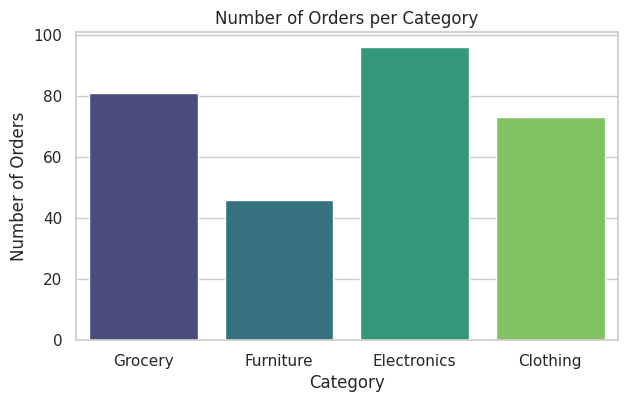

Count plot: shows how many orders each category has. Electronics and Clothing have the most orders, Furniture the fewest.



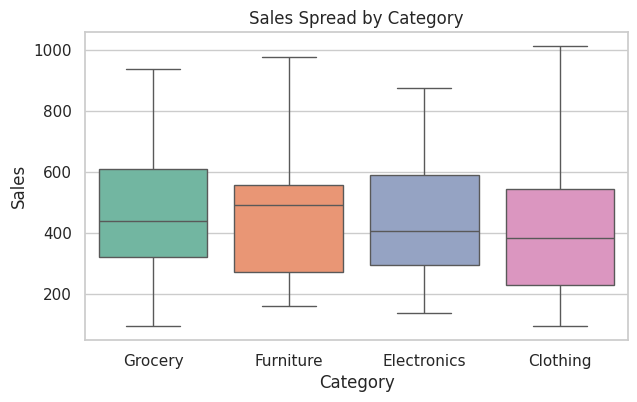

Box plot: compares the median and spread of sales across categories. The categories have similar medians and spreads.



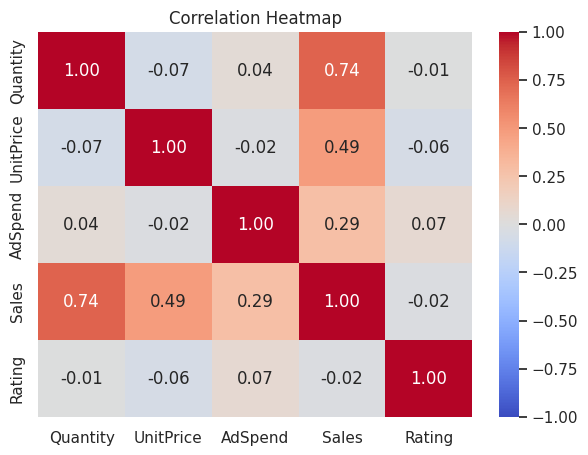

Heatmap: Sales has a strong positive correlation with Quantity, a moderate one with UnitPrice and a weak one with AdSpend. Rating is almost unrelated to Sales.



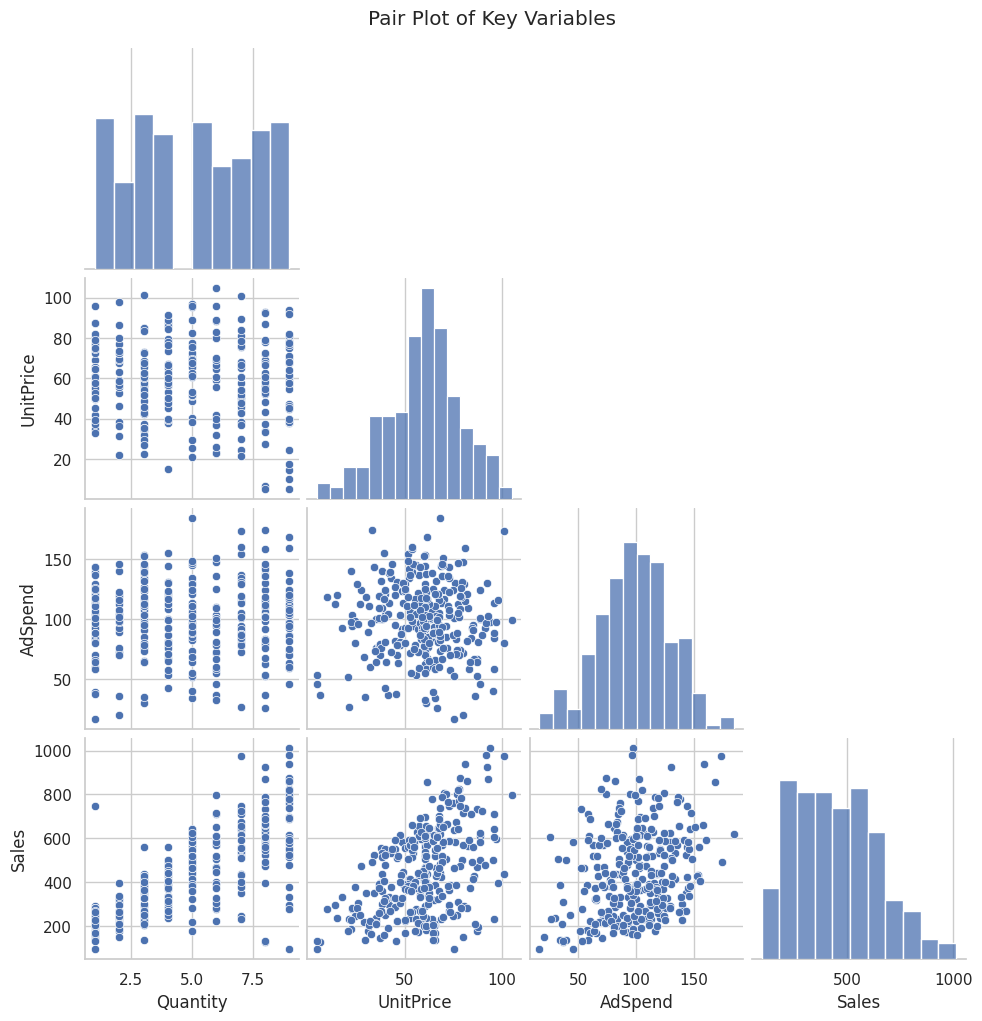

Pair plot: shows every pair of variables as a scatter plot and each variable's distribution on the diagonal. Sales rises with Quantity and UnitPrice.


In [12]:
# Cell 10: Task 6 - Seaborn visualizations (Count Plot, Box Plot, Heatmap, Pair Plot)

# ---------- 1. Count plot ----------
plt.figure(figsize=(7, 4))
sns.countplot(data=clean, x="Category", hue="Category", palette="viridis", legend=False)
plt.title("Number of Orders per Category")
plt.xlabel("Category")
plt.ylabel("Number of Orders")
plt.savefig("outputs/s_count.png", bbox_inches="tight")
plt.show()
print("Count plot: shows how many orders each category has. Electronics and Clothing have the most orders, Furniture the fewest.\n")

# ---------- 2. Box plot ----------
plt.figure(figsize=(7, 4))
sns.boxplot(data=clean, x="Category", y="Sales", hue="Category", palette="Set2", legend=False)
plt.title("Sales Spread by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.savefig("outputs/s_box.png", bbox_inches="tight")
plt.show()
print("Box plot: compares the median and spread of sales across categories. The categories have similar medians and spreads.\n")

# ---------- 3. Heatmap ----------
num_cols = ["Quantity", "UnitPrice", "AdSpend", "Sales", "Rating"]
plt.figure(figsize=(7, 5))
sns.heatmap(clean[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.savefig("outputs/s_heat.png", bbox_inches="tight")
plt.show()
print("Heatmap: Sales has a strong positive correlation with Quantity, a moderate one with UnitPrice and a weak one with AdSpend. Rating is almost unrelated to Sales.\n")

# ---------- 4. Pair plot ----------
g = sns.pairplot(clean[["Quantity", "UnitPrice", "AdSpend", "Sales"]], corner=True)
g.figure.suptitle("Pair Plot of Key Variables", y=1.02)
g.savefig("outputs/s_pair.png")
plt.show()
print("Pair plot: shows every pair of variables as a scatter plot and each variable's distribution on the diagonal. Sales rises with Quantity and UnitPrice.")

Correlation of each variable with Sales:
Quantity     0.736
UnitPrice    0.488
AdSpend      0.289
Rating      -0.018
Name: Sales, dtype: float64


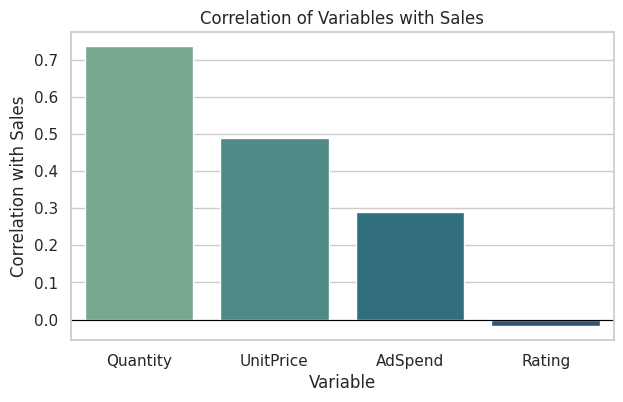


Sales by Category:
             count   mean      sum
Category                          
Clothing        73  406.7  29691.2
Electronics     96  442.5  42478.0
Furniture       46  462.2  21259.0
Grocery         81  469.2  38005.4

Average Sales by Region:
Region
East     441.8
North    443.5
South    435.8
West     457.0
Name: Sales, dtype: float64

Total Sales by Month:
Month
Jan    22523.0
Feb    18437.6
Mar    26460.5
Apr    19504.0
May    29783.1
Jun    14725.4
Name: Sales, dtype: float64


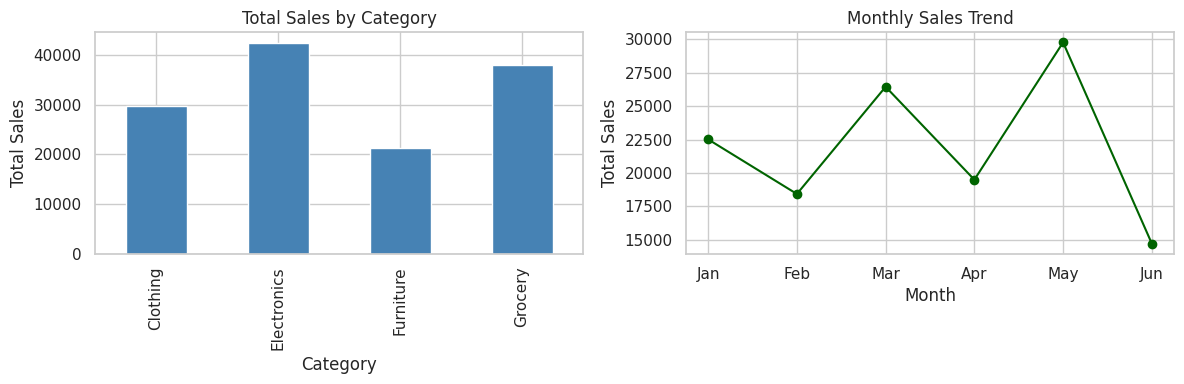


INSIGHTS
1. Quantity has the strongest relationship with Sales (r = 0.74). UnitPrice is next (r = 0.49), which is expected because order value = quantity x price.
2. AdSpend has a positive correlation with Sales (r = 0.29), so higher advertising spend goes together with higher sales.
3. Electronics earns the highest total sales (42,478), while Furniture has the fewest orders (46).
4. Rating has almost no correlation with Sales (r = -0.02), so customer ratings do not predict order value.
5. Sales are highest in May (29,783) and lowest in Jun (14,725), which shows a clear monthly pattern.



In [13]:
# Cell 11: Task 8 - Correlation analysis, patterns and insights

num_cols = ["Quantity", "UnitPrice", "AdSpend", "Sales", "Rating"]

# ---------- Correlation with Sales ----------
corr_sales = clean[num_cols].corr()["Sales"].drop("Sales").sort_values(ascending=False)
print("Correlation of each variable with Sales:")
print(corr_sales.round(3))

plt.figure(figsize=(7, 4))
sns.barplot(x=corr_sales.index, y=corr_sales.values, hue=corr_sales.index, palette="crest", legend=False)
plt.title("Correlation of Variables with Sales")
plt.xlabel("Variable")
plt.ylabel("Correlation with Sales")
plt.axhline(0, color="black", linewidth=0.8)
plt.savefig("outputs/e_corr_sales.png", bbox_inches="tight")
plt.show()

# ---------- Patterns and trends ----------
order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
cat_summary = clean.groupby("Category")["Sales"].agg(["count", "mean", "sum"]).round(1)
region_avg = clean.groupby("Region")["Sales"].mean().round(1)
monthly = clean.groupby("Month")["Sales"].sum().reindex(order).round(1)

print("\nSales by Category:")
print(cat_summary)
print("\nAverage Sales by Region:")
print(region_avg)
print("\nTotal Sales by Month:")
print(monthly)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cat_summary["sum"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Total Sales by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Total Sales")
monthly.plot(kind="line", marker="o", ax=axes[1], color="darkgreen")
axes[1].set_title("Monthly Sales Trend")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Total Sales")
plt.tight_layout()
plt.savefig("outputs/e_patterns.png", bbox_inches="tight")
plt.show()

# ---------- Insights (numbers come directly from the data) ----------
top_var = corr_sales.index[0]
top_cat = cat_summary["sum"].idxmax()
low_cat = cat_summary["count"].idxmin()
best_month = monthly.idxmax()
worst_month = monthly.idxmin()

print(f"""
INSIGHTS
1. {top_var} has the strongest relationship with Sales (r = {corr_sales[top_var]:.2f}). UnitPrice is next (r = {corr_sales['UnitPrice']:.2f}), which is expected because order value = quantity x price.
2. AdSpend has a positive correlation with Sales (r = {corr_sales['AdSpend']:.2f}), so higher advertising spend goes together with higher sales.
3. {top_cat} earns the highest total sales ({cat_summary.loc[top_cat, 'sum']:,.0f}), while {low_cat} has the fewest orders ({cat_summary.loc[low_cat, 'count']}).
4. Rating has almost no correlation with Sales (r = {corr_sales['Rating']:.2f}), so customer ratings do not predict order value.
5. Sales are highest in {best_month} ({monthly[best_month]:,.0f}) and lowest in {worst_month} ({monthly[worst_month]:,.0f}), which shows a clear monthly pattern.
""")

Average Sales by Ad Spend group:
AdGroup
High Ad Spend    479.3
Low Ad Spend     408.7
Name: Sales, dtype: float64

Average Sales by Quantity group:
QtyGroup
Quantity 1-4    301.9
Quantity 5+     560.0
Name: Sales, dtype: float64


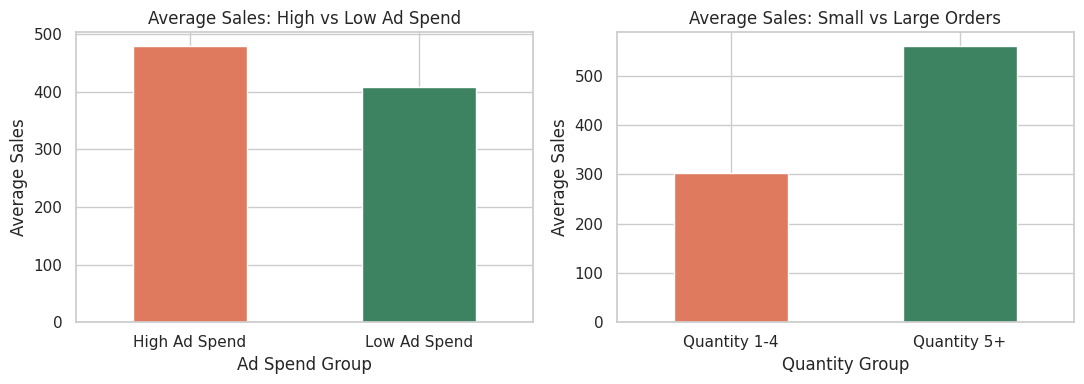


BUSINESS RECOMMENDATIONS

1. Increase and target advertising spend.
   Evidence: AdSpend has a positive correlation with Sales (r = 0.29).
   Orders with high ad spend average 479 in sales versus 409 for low ad spend
   (17% higher). Raise the budget gradually in the best categories and track return on investment.

2. Push bundles and volume discounts to raise quantity per order.
   Evidence: Quantity is the strongest driver of Sales (r = 0.74).
   Orders with 5 or more items average 560 versus 302 for 1-4 items
   (85% higher). Offers such as "buy 5, save 10%" can increase the order value.

3. Plan stock and promotions around the top category and the monthly pattern.
   Evidence: Electronics earns the highest total sales and sales peak in May but are lowest in Jun.
   Stock more of Electronics before May and run special offers in Jun.

4. Add data validation to protect revenue reports.
   Evidence: the raw data had duplicates, negative quantities, inconsistent category names, missing

In [14]:
# Cell 12: Task 9 - Data-driven business recommendations

# ---------- Evidence 1: high vs low ad spend ----------
ad_median = clean["AdSpend"].median()
clean["AdGroup"] = np.where(clean["AdSpend"] >= ad_median, "High Ad Spend", "Low Ad Spend")
ad_avg = clean.groupby("AdGroup")["Sales"].mean().round(1)

# ---------- Evidence 2: small vs large orders (by quantity) ----------
clean["QtyGroup"] = np.where(clean["Quantity"] >= 5, "Quantity 5+", "Quantity 1-4")
qty_avg = clean.groupby("QtyGroup")["Sales"].mean().round(1)

print("Average Sales by Ad Spend group:")
print(ad_avg)
print("\nAverage Sales by Quantity group:")
print(qty_avg)

# Chart to support the recommendations
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ad_avg.plot(kind="bar", ax=axes[0], color=["#e07a5f", "#3d8361"], rot=0)
axes[0].set_title("Average Sales: High vs Low Ad Spend")
axes[0].set_xlabel("Ad Spend Group")
axes[0].set_ylabel("Average Sales")
qty_avg.plot(kind="bar", ax=axes[1], color=["#e07a5f", "#3d8361"], rot=0)
axes[1].set_title("Average Sales: Small vs Large Orders")
axes[1].set_xlabel("Quantity Group")
axes[1].set_ylabel("Average Sales")
plt.tight_layout()
plt.savefig("outputs/r_recommendations.png", bbox_inches="tight")
plt.show()

# ---------- Numbers used in the text ----------
ad_gain = (ad_avg["High Ad Spend"] / ad_avg["Low Ad Spend"] - 1) * 100
qty_gain = (qty_avg["Quantity 5+"] / qty_avg["Quantity 1-4"] - 1) * 100

print(f"""
BUSINESS RECOMMENDATIONS

1. Increase and target advertising spend.
   Evidence: AdSpend has a positive correlation with Sales (r = {corr_sales['AdSpend']:.2f}).
   Orders with high ad spend average {ad_avg['High Ad Spend']:.0f} in sales versus {ad_avg['Low Ad Spend']:.0f} for low ad spend
   ({ad_gain:.0f}% higher). Raise the budget gradually in the best categories and track return on investment.

2. Push bundles and volume discounts to raise quantity per order.
   Evidence: Quantity is the strongest driver of Sales (r = {corr_sales['Quantity']:.2f}).
   Orders with 5 or more items average {qty_avg['Quantity 5+']:.0f} versus {qty_avg['Quantity 1-4']:.0f} for 1-4 items
   ({qty_gain:.0f}% higher). Offers such as "buy 5, save 10%" can increase the order value.

3. Plan stock and promotions around the top category and the monthly pattern.
   Evidence: {top_cat} earns the highest total sales and sales peak in {best_month} but are lowest in {worst_month}.
   Stock more of {top_cat} before {best_month} and run special offers in {worst_month}.

4. Add data validation to protect revenue reports.
   Evidence: the raw data had duplicates, negative quantities, inconsistent category names, missing values and extreme sales values.
   Input checks at order entry will keep revenue figures accurate.
""")

In [15]:
# Cell 13: Create README, list all outputs and download everything as a zip

import shutil

readme = """# InternNova Week 4: Statistics, Data Visualization & EDA

**Author:** Gajanan Harinarayan Raje

## Overview
Statistics, visualization and exploratory data analysis on a synthetic retail sales dataset
(300 orders, generated with Python, seed 42). Dirty data (missing values, duplicates, outliers,
inconsistent text, negative quantities) was added on purpose to demonstrate cleaning.

## Contents
- Week4_Statistics_Visualization_EDA_Gajanan_Raje.ipynb : full code with outputs and explanations
- sales_raw.csv : dataset before cleaning
- sales_clean.csv : dataset after cleaning
- PNG files : all charts and before/after cleaning screenshots

## Tasks covered
1. Mean, Median, Mode
2. Variance and Standard Deviation
3. Correlation and Probability
4. Outlier Detection (IQR method)
5. Matplotlib: line, bar, pie, histogram, scatter
6. Seaborn: count plot, box plot, heatmap, pair plot
7. EDA: data inspection and cleaning
8. EDA: correlation and insights
9. Business recommendations

## Libraries
numpy, pandas, matplotlib, seaborn
"""

with open("outputs/README.md", "w") as f:
    f.write(readme)

print("Files ready for submission:")
for name in sorted(os.listdir("outputs")):
    print(" -", name)

shutil.make_archive("week4_outputs", "zip", "outputs")

try:
    from google.colab import files
    files.download("week4_outputs.zip")
except ImportError:
    print("Not running in Colab. The zip is saved as week4_outputs.zip in the current folder.")

Files ready for submission:
 - README.md
 - after_cleaning.png
 - before_cleaning.png
 - e_corr_sales.png
 - e_patterns.png
 - m_bar.png
 - m_hist.png
 - m_line.png
 - m_pie.png
 - m_scatter.png
 - outliers.png
 - r_recommendations.png
 - s_box.png
 - s_count.png
 - s_heat.png
 - s_pair.png
 - sales_clean.csv
 - sales_raw.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>